<h1><center>Вариационные автоэнкодеры</h1></center>

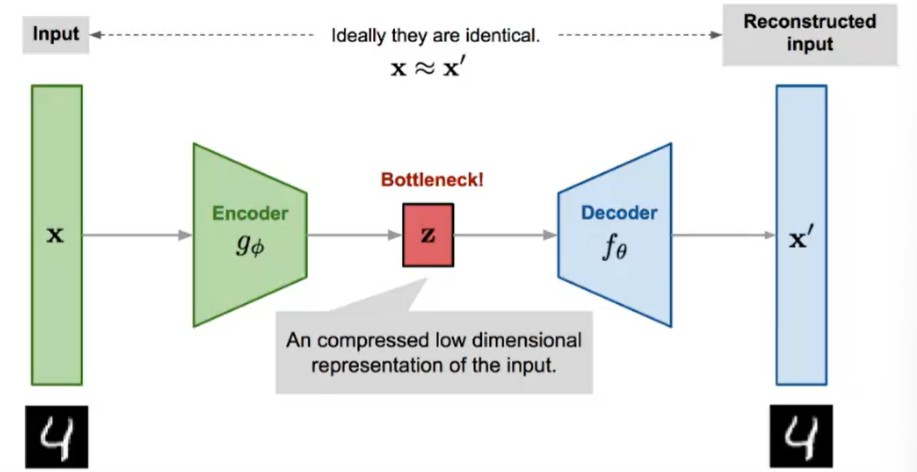

Автоэнкодер - модель глубого машинного обучения. Есть энкодер и декодер. Энкодер принимает изображение, сжимает и отправляет в узкое место (bottleneck - латентное пространство), в котором хранится представление объекта (к примеру тень от объекта при свете от фонарика), и передаём определённые данные в декодер и получаем выход

Узкое место имеет гауссовское смещение, т.е возможно генерировать новые данные на основе старых.

Проще и легче остальных моделей генерации данных.

In [13]:
import torch
from torch import nn
from torchvision.datasets import MNIST
from torchvision import transforms as T
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np

In [14]:
transform = T.Compose([
    T.ToTensor(),
    T.Resize((32, 32)),
    T.Normalize([.5], [.5])
    ])


train_set = MNIST(root='./SimpleNN', train=True,
                  download=True, transform=transform)
valid_set = MNIST(root='./SimpleNN', train=False,
                  download=True, transform=transform)

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [16]:
class VAEEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=5, padding=2, stride=2),
            nn.InstanceNorm2d(8),
            nn.ReLU(),

            nn.Conv2d(8, 16, kernel_size=5, padding=2, stride=2),
            nn.InstanceNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=5, padding=2, stride=2),
            nn.InstanceNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 128, kernel_size=4)
        )

    def forward(self, x):
        z = self.net(x)
        z_mu, z_log_sigma = z[:, :64], z[:, 64:]
        return z_mu, z_log_sigma

class VAEDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4),
            nn.InstanceNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 16, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2, mode='bilinear'),
            nn.InstanceNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 8, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2, mode='bilinear'),
            nn.InstanceNorm2d(8),
            nn.ReLU(),

            nn.Conv2d(8, 1, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2, mode='bilinear')
        )

    def forward(self, z):
        x_mu = self.net(z)
        return x_mu
    
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = VAEEncoder()
        self.decoder = VAEDecoder()

    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, x):
        return self.decoder(x)
    
    def new_parametrezation(self, mu, log_sigma, eps):
        return mu + torch.exp(.5 * log_sigma) * eps
    
    def forward(self, x):
        z_mu, z_log_sigma = self.encode(x)
        eps = torch.randn_like(z_mu)
        z = self.new_parametrezation(z_mu, z_log_sigma, eps)
        x_mu = self.decode(z)
        return z_mu, z_log_sigma, x_mu
    
class VAELoss(nn.Module):
    def forward(self, x, z_mu, z_log_sigma, x_mu):
        z_sigma = torch.exp(z_log_sigma)
        rec_loss = ((x - x_mu).square().sum() / x.shape[0])
        rec_loss = .5 * rec_loss
        
        kl_loss = (-1 + -z_log_sigma + z_sigma + z_mu.square()).sum() / x.shape[0]
        kl_loss = .5 * kl_loss
        return rec_loss + kl_loss 

In [17]:
vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=3e-4)
criterion = VAELoss()

train_loader = DataLoader(train_set, batch_size=128,
                          pin_memory=True, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128,
                          pin_memory=True, shuffle=False)

In [ ]:
def VAE_learn(vae, optimizer, criterion, train_set, valid_set, train_loader, valid_loader, device, num_epochs = 30):
    train_loss = [.0 for _ in range(num_epochs)]
    valid_loss = [.0 for _ in range(num_epochs)] 
    for epoch in range(num_epochs):
        if (epoch % 10 == 0) or (epoch == num_epochs - 1):
            torch.save(vae.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_13/vae_weights_{epoch}.pt')
        vae.train()
        for images, _ in tqdm(train_loader, desc=f'Training {epoch:3d}/{num_epochs:3d}'):
            optimizer.zero_grad()
            images = images.to(device)
            out = vae(images)
            loss = criterion(images, *out)
            loss.backward()
            optimizer.step()
            train_loss[epoch] += loss.item() * images.shape[0]

        vae.eval()
        with torch.inference_mode():
            for images, _ in tqdm(valid_loader, desc=f'validating: {epoch:3d}/{num_epochs:3d}'):
                images = images.to(device)
                out = vae(images)
                loss = criterion(images, *out)
                valid_loss[epoch] += loss.item() * images.shape[0]

        train_loss[epoch] /= len(train_set)
        valid_loss[epoch] /= len(valid_set)

        print(f'{(epoch + 1):3d}/{num_epochs:3d}: train_loss: {train_loss[epoch]:2.3f} \
              valid_loss: {valid_loss[epoch]:2.3f}')
    return vae, optimizer, train_loss, valid_loss

In [9]:
vae, optimizer, train_loss_hist, valid_loss_hist = VAE_learn(vae, optimizer, criterion,
                                                             train_set, valid_set,
                                                             train_loader, valid_loader,
                                                             device, 60)

Training   0/ 60:   0%|          | 0/469 [00:00<?, ?it/s]

validating:   0/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

  1/ 60: train_loss: 73.104               valid_loss: 68.031


Training   1/ 60:   0%|          | 0/469 [00:00<?, ?it/s]

validating:   1/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

...

validating:  58/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 59/ 60: train_loss: 43.790               valid_loss: 43.621


Training  59/ 60:   0%|          | 0/469 [00:00<?, ?it/s]

validating:  59/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 60/ 60: train_loss: 43.779               valid_loss: 43.589


Text(0.5, 1.0, 'VAE criterions')

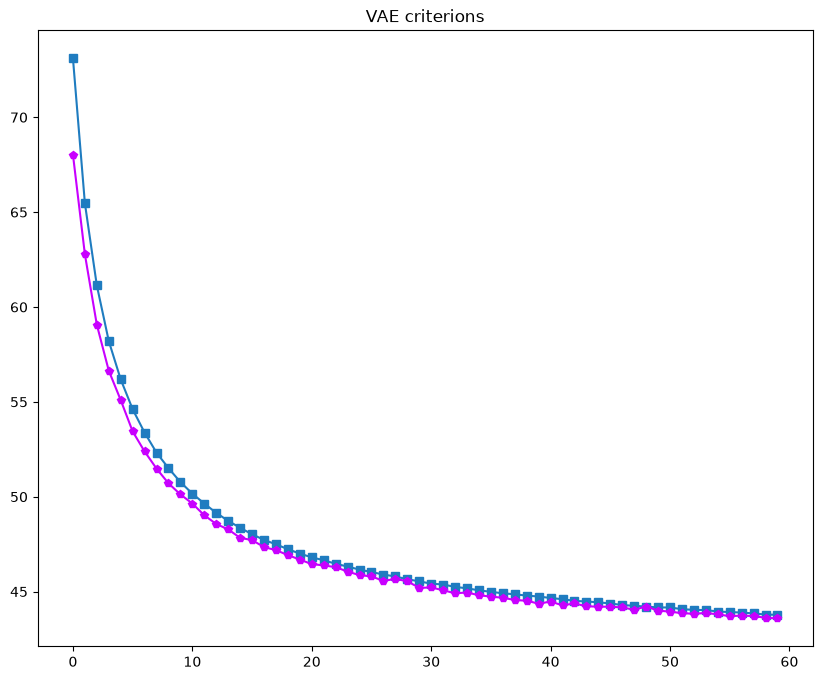

In [11]:
plt.figure(figsize=(10, 8))
plt.plot(range(len(train_loss_hist)), train_loss_hist, color='#1F7CC0', marker='s')
plt.plot(range(len(valid_loss_hist)), valid_loss_hist, color='#C800FF', marker='p')
plt.title("VAE criterions")

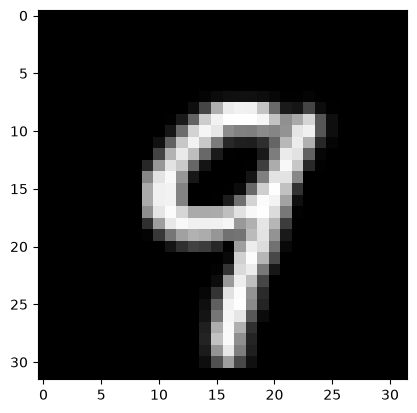

In [22]:
image = valid_set[12][0].unsqueeze(0)
plt.imshow((image[0][0] + 1) / 2, cmap='grey')

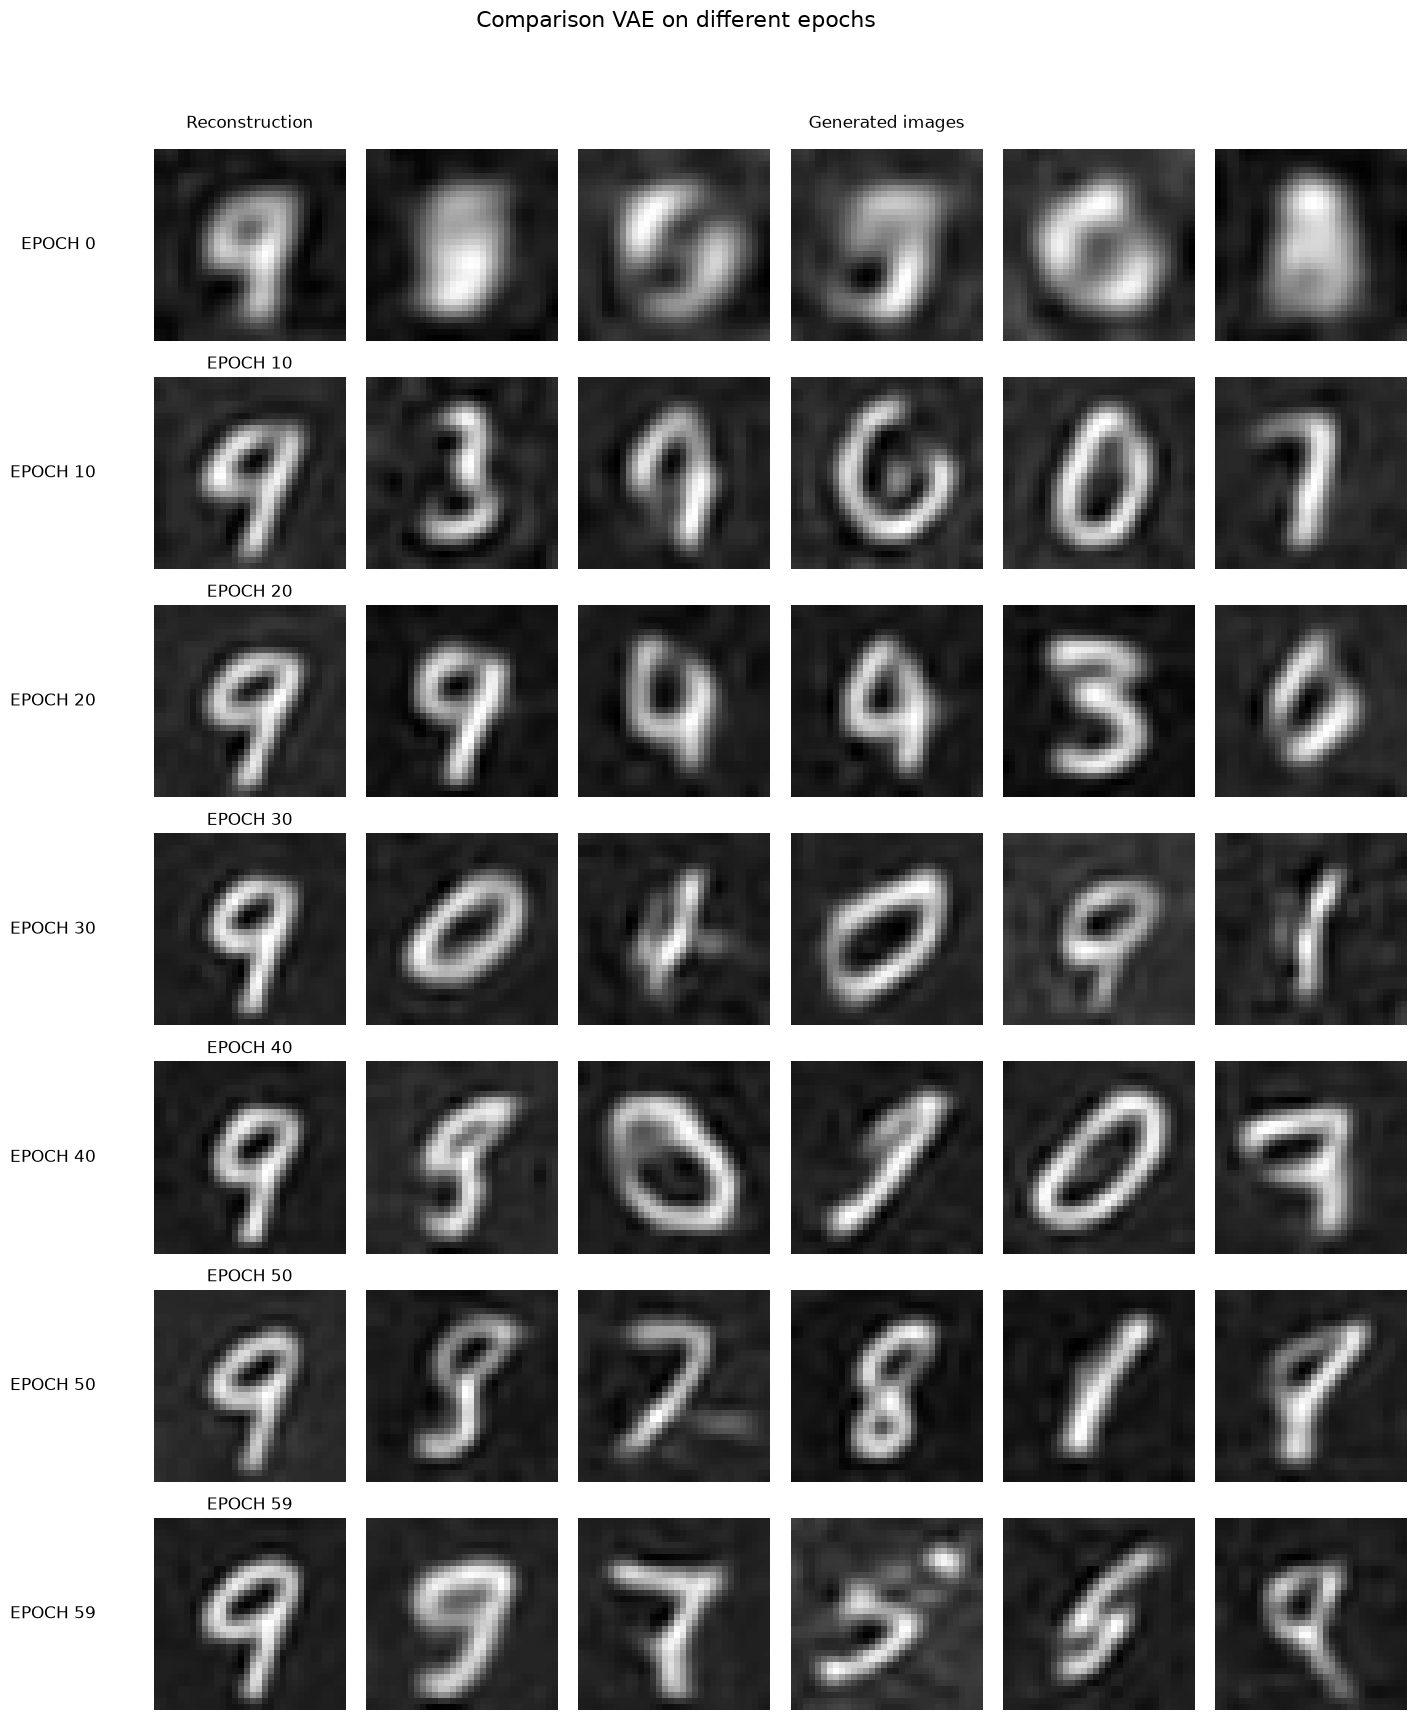

In [60]:
import glob


files = glob.glob('D:/MIREA/DPO/Learning/Practic2_13/vae_weights_*.pt')
number_to_represent = len(files)
epochs = [int(f[46:-3]) for f in files]
len_epochs = len(epochs)
fig, ax = plt.subplots(len_epochs, 6, figsize=(15, 2.5 * len_epochs))
plt.suptitle("Comparison VAE on different epochs", fontsize=16)

for row, epoch in enumerate(epochs):
    vae_repr = VAE()
    vae_repr_weights = torch.load(f'D:/MIREA/DPO/Learning/Practic2_13/vae_weights_{epoch}.pt')
    vae_repr.load_state_dict(vae_repr_weights)
    vae_repr = vae_repr.to('cpu')
    with torch.inference_mode():
        _, _, rec_image = vae_repr(image)
    
    ax[row][0].imshow((rec_image[0, 0] + 1) / 2, cmap='gray')
    z_mu, z_log_sigma = vae_repr.encode(image)
    ax[row][0].set_title(f'EPOCH {epoch}')
    ax[row][0].axis('off')

    if row == 0:
        ax[row][0].set_title("Reconstruction", fontsize=12, pad=15)
    
    ax[row][0].text(-0.3, 0.5, f'EPOCH {epoch}', fontsize=12,
                    va='center', ha='right', transform=ax[row][0].transAxes)

    for col in range(5):
        with torch.inference_mode():
            z = torch.randn_like(z_mu)
            rec_image = vae_repr.decode(z)
            ax[row][col + 1].imshow((rec_image[0, 0] + 1) / 2, cmap='gray')
            ax[row][col + 1].axis('off')
            if (row == 0) and (col == 2):
                ax[row][col + 1].set_title("Generated images", fontsize=12, pad=15)

plt.tight_layout(rect=[0.05, 0, 1, 0.95])
plt.show()